In [1]:

import pandas as pd
import numpy as np

# Generate synthetic GPS data
np.random.seed(42)

number_of_records = 1000

# Generate anonymous device IDs
device_ids = [
    f"D{np.random.randint(1, 101):03d}"
    for _ in range(number_of_records)
]

# Generate fictional Hyderabad-area coordinates
latitude = np.random.uniform(
    17.35, 17.45, number_of_records
)

longitude = np.random.uniform(
    78.40, 78.55, number_of_records
)

# Generate timestamps
timestamps = pd.date_range(
    start="2026-11-10 06:00:00",
    periods=number_of_records,
    freq="5min"
)

# Create DataFrame
df = pd.DataFrame({
    "DeviceID": device_ids,
    "Latitude": latitude,
    "Longitude": longitude,
    "Timestamp": timestamps
})

# Display the dataset
print("GeoPulse GPS Dataset")
print("Total records:", len(df))
print("Unique devices:", df["DeviceID"].nunique())

display(df.head(10))

# Save dataset
df.to_csv("geopulse_gps_data.csv", index=False)

print("Dataset generated successfully!")


GeoPulse GPS Dataset
Total records: 1000
Unique devices: 100


,DeviceID,Latitude,Longitude,Timestamp
0,D052,17.408684,78.439467,2026-11-10 06:00:00
1,D093,17.424544,78.454020,2026-11-10 06:05:00
2,D015,17.393166,78.413146,2026-11-10 06:10:00
3,D072,17.362758,78.540544,2026-11-10 06:15:00
4,D061,17.378378,78.483070,2026-11-10 06:20:00
5,D021,17.386308,78.445829,2026-11-10 06:25:00
6,D083,17.414592,78.459547,2026-11-10 06:30:00
7,D087,17.407078,78.467080,2026-11-10 06:35:00
8,D075,17.385610,78.490089,2026-11-10 06:40:00
9,D075,17.448652,78.477352,2026-11-10 06:45:00


Dataset generated successfully!


In [2]:

import pandas as pd
import folium

# Load generated GPS dataset
df = pd.read_csv("geopulse_gps_data.csv")

# Create Hyderabad map
m = folium.Map(
    location=[17.3850, 78.4867],
    zoom_start=12
)

# Display first 100 GPS locations
for _, row in df.head(100).iterrows():
    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=4,
        popup=f'Device: {row["DeviceID"]}',
        color="blue",
        fill=True
    ).add_to(m)

# Display map
display(m)


In [3]:
!pip install -q plotly

In [4]:

import pandas as pd
import plotly.express as px

# Load GPS dataset
df = pd.read_csv("geopulse_gps_data.csv")

# Plot GPS locations
fig = px.scatter_map(
    df.head(100),
    lat="Latitude",
    lon="Longitude",
    color="DeviceID",
    hover_data=["Timestamp"],
    zoom=11,
    height=600,
    title="GeoPulse - Hyderabad GPS Locations"
)

fig.update_layout(
    map_style="open-street-map"
)

fig.show()


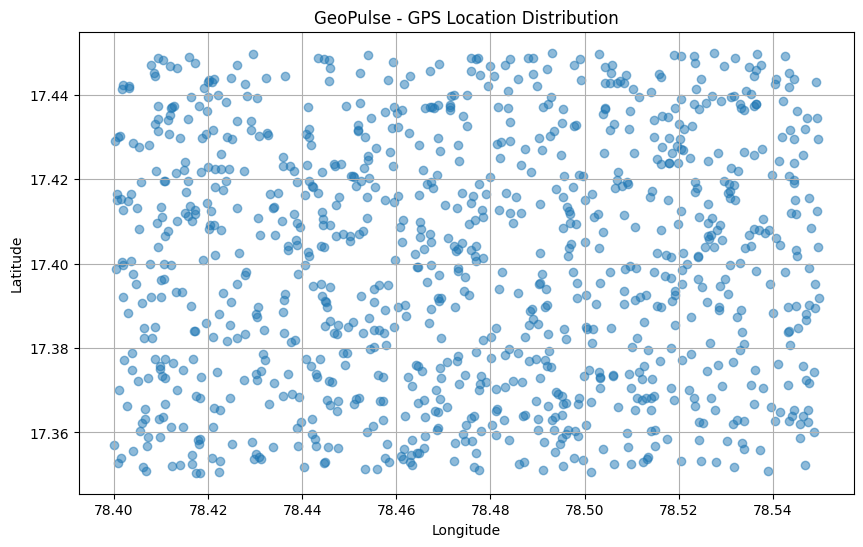

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Load GPS dataset
df = pd.read_csv("geopulse_gps_data.csv")

# Plot GPS coordinates
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("GeoPulse - GPS Location Distribution")
plt.grid(True)

plt.show()


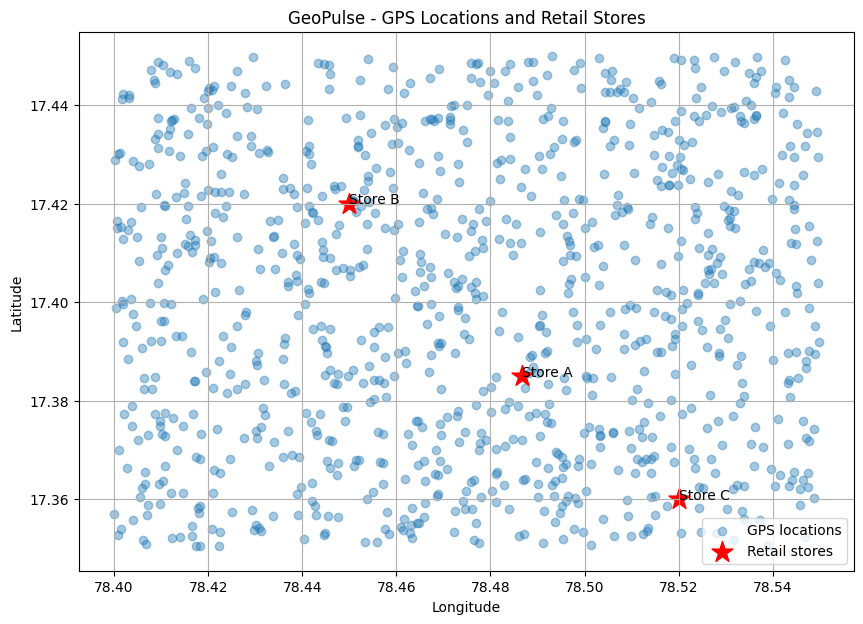

Retail store locations created successfully!


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

# Define retail stores
stores = pd.DataFrame({
    "StoreID": ["Store A", "Store B", "Store C"],
    "Latitude": [17.3850, 17.4200, 17.3600],
    "Longitude": [78.4867, 78.4500, 78.5200]
})

# Load GPS dataset
gps = pd.read_csv("geopulse_gps_data.csv")

# Plot GPS locations
plt.figure(figsize=(10, 7))

plt.scatter(
    gps["Longitude"],
    gps["Latitude"],
    label="GPS locations",
    alpha=0.4
)

# Plot stores
plt.scatter(
    stores["Longitude"],
    stores["Latitude"],
    color="red",
    marker="*",
    s=250,
    label="Retail stores"
)

for _, store in stores.iterrows():
    plt.annotate(
        store["StoreID"],
        (store["Longitude"], store["Latitude"])
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("GeoPulse - GPS Locations and Retail Stores")
plt.legend()
plt.grid(True)
plt.show()

print("Retail store locations created successfully!")
